# 03 · Hypothesis tests (H1–H3)

| Hypothesis | Statement | Test |
|---|---|---|
| **H1a** | IPP capital in finance grows exponentially | Log-linear trend with Newey–West SEs; exponential vs linear fit |
| **H1b** | IPP capital grows faster in finance than elsewhere, and faster after 2010 | Panel regression of annual IPP growth with year effects |
| **H1c** | There is a structural break in finance's IPP growth | Chow test at 2010; Quandt–Andrews sup-F with bootstrap p-value; PELT change points |
| **H2** | IPP capital deepening widens the productivity–pay gap | Two-way fixed effects, clustered and Driscoll–Kraay SEs |
| **H3** | IPP capital deepening lowers the labour share, more strongly in finance and after 2010 | Two-way FE with interactions; first differences; randomization inference; double machine learning |

**Treatment variable (revised).** The main measure of IPP capital deepening is **log real IPP capital per worker** (BEA chain-type quantity index of the IPP net stock ÷ FTE employees), lagged one year. The earlier measure, IPP stock ÷ value added, shares its denominator with the labour share (compensation ÷ value added). That creates a spurious correlation ("division bias") whenever value added moves, so it is reported only as a secondary specification. The control is log real equipment per worker.

**Inference for the finance difference.** Only three industries are in finance, so the headline test of the finance interaction is randomization inference. It compares the actual estimate with those obtained when the finance label is given to 1,000 random groups of three industries.

Main p-values are adjusted for multiple testing with the Holm–Bonferroni method at the end.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "src" / "exgap").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from exgap.build_panel import load_panel
from exgap import stats as st
from exgap.config import BREAK_YEAR, RANDOM_STATE
st.set_style()
df = load_panel().sort_values(["code", "year"])
g = df.groupby("code")
TREAT, CTRL_VAR = "log_ipp_pw", "log_eq_pw"        # main treatment and control (per worker)
df["L_ipp"] = g[TREAT].shift(1)
df["L_eq"] = g[CTRL_VAR].shift(1)
for v in ["log_ipp_intensity", "log_eq_intensity", "ipp_share_of_capital", "ipp_inv_rate"]:   # secondary measures
    if v in df:
        df[f"L_{v}"] = g[v].shift(1)
df["fin_x_L_ipp"] = df["finance"] * df["L_ipp"]
df["post_x_L_ipp"] = df["post_break"] * df["L_ipp"]
df["fin_post_x_L_ipp"] = df["finance"] * df["post_break"] * df["L_ipp"]
df["fin_x_post"] = df["finance"] * df["post_break"]
CONTROLS = ["L_eq"]
TESTS = []   # headline tests: direction-aware, Holm-corrected at the end
def record(name, estimate, p_two, expected):
    TESTS.append({"hypothesis": name, "expected_sign": expected, "estimate": float(estimate),
                  "p_two_sided": float(p_two), "p_one_sided": st.directional(estimate, p_two, expected)})
print(df.code.nunique(), "industries;", df.year.min(), "-", df.year.max())

64 industries; 1997 - 2025


## H1a · Exponential growth of IPP capital
The series is the real (chain-type quantity) IPP net stock where available, otherwise the nominal stock.

In [3]:
yvar = "ipp_qty" if "ipp_qty" in df and df["ipp_qty"].notna().any() else "ipp_stock"
series = {}
for (code, name), s in df[df.finance == 1].dropna(subset=[yvar]).groupby(["code", "name"]):
    series[f"{code} {name[:40]}"] = s.set_index("year")[yvar]
# group aggregates: index each industry to its first year, then take the VA-weighted mean of log indices
def group_index(sub):
    sub = sub.dropna(subset=[yvar]).copy()
    sub["lidx"] = np.log(sub[yvar]) - sub.groupby("code")[yvar].transform(lambda s: np.log(s.iloc[0]))
    w = sub.groupby("year").apply(lambda d: np.average(d.lidx, weights=d.va_nom))
    return np.exp(w) * 100
series["ALL FINANCE (VA-weighted)"] = group_index(df[df.finance == 1])
series["ALL NON-FINANCE (VA-weighted)"] = group_index(df[df.finance == 0])

h1a = pd.DataFrame({k: st.loglinear_trend(pd.Series(v.index), pd.Series(v.values)) for k, v in series.items()}).T
h1a = h1a[["growth_rate", "se", "p", "doubling_years", "r2_log", "rmse_exponential", "rmse_linear", "exp_beats_linear", "n"]]
st.save_table(h1a, "h1a_exponential_trends", caption="H1a: log-linear trend growth of IPP capital")
record("H1a Finance IPP stock grows (trend growth > 0)", h1a.loc["ALL FINANCE (VA-weighted)", "growth_rate"],
       h1a.loc["ALL FINANCE (VA-weighted)", "p"], "+")
h1a.style.format({"growth_rate": "{:.2%}", "se": "{:.4f}", "p": "{:.3g}", "doubling_years": "{:.1f}",
                  "r2_log": "{:.3f}", "rmse_exponential": "{:.2f}", "rmse_linear": "{:.2f}"})

,growth_rate,se,p,doubling_years,r2_log,rmse_exponential,rmse_linear,exp_beats_linear,n
"521CI Federal Reserve banks, credit intermedia",7.06%,0.0053,1.12e-37,10.2,0.935,34.07,52.57,True,29
"523 Securities, commodity contracts, and inv",10.00%,0.0057,1.71e-62,7.3,0.965,23.68,41.66,True,29
524 Insurance carriers and related activitie,7.54%,0.0038,9.71e-83,9.5,0.970,8.70,19.83,True,29
ALL FINANCE (VA-weighted),7.75%,0.0040,4.64e-76,9.3,0.966,58.63,108.00,True,29
ALL NON-FINANCE (VA-weighted),6.56%,0.0027,1.45e-125,10.9,0.977,28.42,58.73,True,29


## H1b · Is IPP growth faster in finance, and after 2010?
Dependent variable: annual log growth of the IPP stock. Year effects absorb common shocks; SEs clustered by industry.

In [4]:
h1b_models = []
r1 = st.panel_fe(df, "g_ipp_stock", ["finance"], entity_effects=False, time_effects=True)
h1b_models.append(st.tidy(r1, "(1) Finance premium"))
r2 = st.panel_fe(df, "g_ipp_stock", ["finance", "fin_x_post"], entity_effects=False, time_effects=True)
h1b_models.append(st.tidy(r2, "(2) + Finance x post-2010"))
r3 = st.panel_fe(df, "g_ipp_stock", ["fin_x_post"], entity_effects=True, time_effects=True)
h1b_models.append(st.tidy(r3, "(3) Industry FE"))
h1b = st.regression_table(h1b_models, ["finance", "fin_x_post"])
st.save_table(h1b, "h1b_growth_premium", caption="H1b: IPP growth premium in finance")
_r = h1b_models[0].query("term=='finance'").iloc[0]
record("H1b Finance IPP growth premium", _r.coef, _r.p, "+")
_r = h1b_models[2].query("term=='fin_x_post'").iloc[0]
record("H1b Extra post-2010 acceleration in finance", _r.coef, _r.p, "+")
h1b

,(1) Finance premium,(2) + Finance x post-2010,(3) Industry FE
finance,0.023***,0.028**,
finance (se),(0.007),(0.012),
fin_x_post,,-0.010,-0.010
fin_x_post (se),,(0.015),(0.016)
Observations,1792,1792,1792
Industries,64,64,64
R2 (net of FE),0.004,0.004,0.000


## H1c · Structural breaks in finance's IPP trajectory

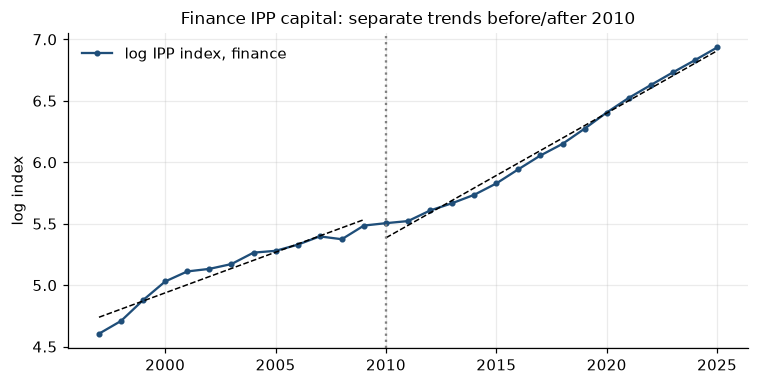

,statistic,p_value,detail
Chow test,36.170240,4.174280e-08,break imposed at 2010 (assumes independent err...
Quandt-Andrews sup-F,42.483090,1.800000e-02,estimated break year 2011; moving-block bootst...
Growth difference (HAC),0.017236,4.398703e-01,"post minus pre mean log growth, Newey-West SE ..."
PELT,NaN,NaN,PELT change points in growth: none
Growth pre,0.073319,NaN,mean log growth before break
Growth post,0.090554,NaN,mean log growth after break


In [5]:
fin_series = series["ALL FINANCE (VA-weighted)"].dropna()
yrs, ly = fin_series.index.values.astype(int), np.log(fin_series.values)
chow = st.chow_test(yrs, ly, BREAK_YEAR)
supf = st.sup_f_break(yrs, ly)
growth = np.diff(ly)
pelt = st.pelt_breaks(growth, yrs[1:])
hac = st.growth_break_hac(yrs, ly, BREAK_YEAR)
h1c = pd.DataFrame({
    "statistic": [chow["F"], supf["supF"], hac["diff"], np.nan, hac["growth_pre"], hac["growth_post"]],
    "p_value": [chow["p"], supf["p_boot"], hac["p"], np.nan, np.nan, np.nan],
    "detail": [f"break imposed at {BREAK_YEAR} (assumes independent errors)",
               f"estimated break year {supf['break_year']}; moving-block bootstrap p-value",
               "post minus pre mean log growth, Newey-West SE (preferred test)",
               f"PELT change points in growth: {pelt or 'none'}", "mean log growth before break", "mean log growth after break"],
}, index=["Chow test", "Quandt-Andrews sup-F", "Growth difference (HAC)", "PELT", "Growth pre", "Growth post"])
st.save_table(h1c, "h1c_structural_breaks", caption="H1c: structural breaks in finance IPP capital")
record(f"H1c Finance IPP growth higher after {BREAK_YEAR} (HAC)", hac["diff"], hac["p"], "+")

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(yrs, ly, "o-", color=st.PALETTE["finance"], ms=3, label="log IPP index, finance")
for side in [yrs < BREAK_YEAR, yrs >= BREAK_YEAR]:
    b = np.polyfit(yrs[side], ly[side], 1); ax.plot(yrs[side], np.polyval(b, yrs[side]), "--", color="k", lw=1)
ax.axvline(BREAK_YEAR, color="grey", ls=":"); ax.set_ylabel("log index"); ax.legend()
ax.set_title(f"Finance IPP capital: separate trends before/after {BREAK_YEAR}")
st.savefig(fig, "fig8_h1c_break"); plt.show()
h1c

## H2 · IPP capital deepening and the productivity–pay gap

$$\text{Gap}_{it} = \beta\,\log(\text{IPP}/\text{FTE})_{i,t-1} + \gamma'X_{i,t-1} + \alpha_i + \tau_t + \varepsilon_{it}$$

First, the exact decomposition of the gap for finance (value-added weighted): gap = −Δ log(labour share) + Δ log(consumer price / output price).

In [6]:
d = df.dropna(subset=["prod_pay_gap", "labor_share", "log_va_price", "pcepi"]).copy()
d["log_ls_idx"] = np.log(d.labor_share) - d.groupby("code")["labor_share"].transform(lambda s: np.log(s.iloc[0]))
d["log_pc_pva_idx"] = (np.log(d.pcepi) - d.log_va_price) - d.groupby("code").apply(
    lambda s: (np.log(s.pcepi) - s.log_va_price).iloc[0]).reindex(d.code).values
d["implied_gap"] = -d.log_ls_idx + d.log_pc_pva_idx
decomp = (d[d.finance == 1].groupby("year").apply(lambda s: pd.Series({
            "gap": np.average(s.prod_pay_gap, weights=s.va_nom),
            "from_labour_share": np.average(-s.log_ls_idx, weights=s.va_nom),
            "from_price_wedge": np.average(s.log_pc_pva_idx, weights=s.va_nom)})))
print("Max absolute decomposition error:", float((d.prod_pay_gap - d.implied_gap).abs().max().round(6)))
st.save_table(decomp.round(4), "h2_gap_decomposition_finance", caption="Decomposition of the productivity-pay gap, finance")
decomp.tail(8).round(3)

Max absolute decomposition error: 0.0


,gap,from_labour_share,from_price_wedge
year,,,
2018,-0.029,0.087,-0.116
2019,-0.023,0.093,-0.116
2020,-0.068,0.058,-0.126
2021,-0.058,0.055,-0.114
2022,0.001,0.098,-0.096
2023,0.062,0.201,-0.140
2024,0.056,0.233,-0.178
2025,0.053,0.266,-0.213


In [7]:
h2_models = []
for label, xs, cov in [("(1) Baseline, clustered", ["L_ipp"] + CONTROLS, "clustered"),
                        ("(2) Finance interaction", ["L_ipp", "fin_x_L_ipp"] + CONTROLS, "clustered"),
                        ("(3) Driscoll-Kraay", ["L_ipp", "fin_x_L_ipp"] + CONTROLS, "driscoll-kraay")]:
    h2_models.append(st.tidy(st.panel_fe(df, "prod_pay_gap", xs, cov=cov), label))
h2 = st.regression_table(h2_models, ["L_ipp", "fin_x_L_ipp"] + CONTROLS)
st.save_table(h2, "h2_prod_pay_gap", caption="H2: IPP intensity and the productivity-pay gap (two-way FE)")
_r = h2_models[0].query("term=='L_ipp'").iloc[0]
record("H2 IPP intensity widens the productivity-pay gap (all)", _r.coef, _r.p, "+")
_lc = st.lincomb(st.panel_fe(df, "prod_pay_gap", ["L_ipp", "fin_x_L_ipp"] + CONTROLS),
                 ["L_ipp", "fin_x_L_ipp"])
record("H2 ... in finance (beta + beta_fin)", _lc["estimate"], _lc["p"], "+")
h2

,"(1) Baseline, clustered",(2) Finance interaction,(3) Driscoll-Kraay
L_ipp,0.019,0.029,0.029
L_ipp (se),(0.046),(0.047),(0.022)
fin_x_L_ipp,,-0.142,-0.142***
fin_x_L_ipp (se),,(0.090),(0.040)
L_eq,0.226*,0.209,0.209***
L_eq (se),(0.137),(0.139),(0.040)
Observations,1728,1728,1728
Industries,64,64,64
R2 (net of FE),0.037,0.044,0.044


## H3 · IPP capital deepening and the labour share

$$LS_{it} = \beta_1 \log(\text{IPP}/\text{FTE})_{i,t-1} + \beta_2 (\text{Fin}_i \times \log(\text{IPP}/\text{FTE})_{i,t-1}) + \beta_3 (\text{Post}_t \times \cdot) + \beta_4 (\text{Fin}_i\times\text{Post}_t\times \cdot) + \gamma' X + \alpha_i + \tau_t + \varepsilon_{it}$$

H3 predicts $\beta_1 < 0$ and $\beta_2 < 0$ (a stronger effect in finance).

In [8]:
specs = [
    ("(1) Baseline", ["L_ipp"] + CONTROLS, "clustered"),
    ("(2) x Finance", ["L_ipp", "fin_x_L_ipp"] + CONTROLS, "clustered"),
    ("(3) x Post-2010", ["L_ipp", "post_x_L_ipp"] + CONTROLS, "clustered"),
    ("(4) Triple", ["L_ipp", "fin_x_L_ipp", "post_x_L_ipp", "fin_post_x_L_ipp"] + CONTROLS, "clustered"),
    ("(5) Triple, Driscoll-Kraay", ["L_ipp", "fin_x_L_ipp", "post_x_L_ipp", "fin_post_x_L_ipp"] + CONTROLS, "driscoll-kraay"),
    ("(6) Triple, two-way cluster", ["L_ipp", "fin_x_L_ipp", "post_x_L_ipp", "fin_post_x_L_ipp"] + CONTROLS, "twoway"),
]
h3_models = [st.tidy(st.panel_fe(df, "labor_share", xs, cov=cov), label) for label, xs, cov in specs]
terms = ["L_ipp", "fin_x_L_ipp", "post_x_L_ipp", "fin_post_x_L_ipp"] + CONTROLS
h3 = st.regression_table(h3_models, terms)
st.save_table(h3, "h3_labor_share_fe", caption="H3: IPP intensity and the labour share (two-way FE)")
_r = h3_models[0].query("term=='L_ipp'").iloc[0]
record("H3 IPP intensity lowers the labour share (all)", _r.coef, _r.p, "-")
# (the finance difference is recorded after the randomization-inference cell below)
h3

,(1) Baseline,(2) x Finance,(3) x Post-2010,(4) Triple,"(5) Triple, Driscoll-Kraay","(6) Triple, two-way cluster"
L_ipp,0.013,0.017,0.013,0.017,0.017***,0.017
L_ipp (se),(0.014),(0.014),(0.014),(0.014),(0.006),(0.014)
fin_x_L_ipp,,-0.056***,,-0.042***,-0.042,-0.042**
fin_x_L_ipp (se),,(0.010),,(0.013),(0.026),(0.017)
post_x_L_ipp,,,-0.011**,-0.012**,-0.012***,-0.012**
post_x_L_ipp (se),,,(0.005),(0.005),(0.003),(0.005)
fin_post_x_L_ipp,,,,0.002,0.002,0.002
fin_post_x_L_ipp (se),,,,(0.002),(0.005),(0.003)
L_eq,-0.093***,-0.100***,-0.083**,-0.091**,-0.091***,-0.091***
L_eq (se),(0.034),(0.034),(0.036),(0.036),(0.028),(0.033)


### Implied effect for finance
The marginal effect of log IPP capital per worker on the labour share in finance is β₁ + β₂ (from model 2), with a standard error from the coefficient covariance matrix.

In [9]:
res2 = st.panel_fe(df, "labor_share", ["L_ipp", "fin_x_L_ipp"] + CONTROLS)
b, V = res2.params, res2.cov
eff = b["L_ipp"] + b["fin_x_L_ipp"]
se = np.sqrt(V.loc["L_ipp", "L_ipp"] + V.loc["fin_x_L_ipp", "fin_x_L_ipp"]
             + 2 * V.loc["L_ipp", "fin_x_L_ipp"])
from scipy import stats as sps
p = 2 * (1 - sps.norm.cdf(abs(eff / se)))
me = pd.DataFrame({"effect": [b["L_ipp"], eff], "se": [res2.std_errors["L_ipp"], se]},
                  index=["Non-finance", "Finance"])
me["p"] = [res2.pvalues["L_ipp"], p]
me["effect_of_doubling_IPP_intensity_pp"] = me["effect"] * np.log(2) * 100
record("H3 Net effect in finance (beta + beta_fin)", eff, p, "-")
st.save_table(me.round(4), "h3_marginal_effects", caption="Marginal effect of IPP intensity on the labour share")
me.round(4)

,effect,se,p,effect_of_doubling_IPP_intensity_pp
Non-finance,0.0165,0.0142,0.2444,1.1464
Finance,-0.0399,0.0125,0.0014,-2.7683


### Randomization inference for the finance difference (headline test)

The finance label is reassigned to 1,000 random groups of three industries, and the finance interaction (model 2) is re-estimated each time. The one-sided p-value is the share of random groups with an interaction at least as negative as the real finance group's.

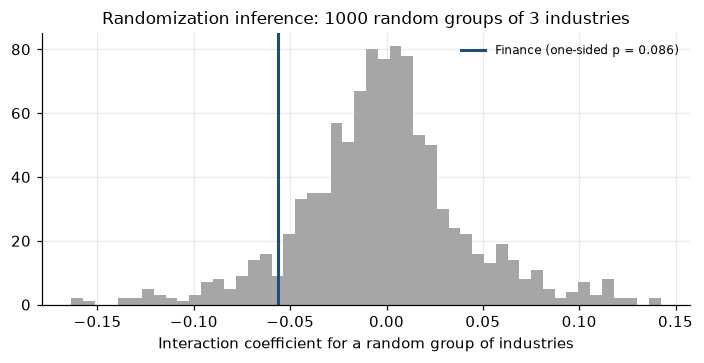

,actual_interaction,one_sided_p_randomization,clustered_p_two_sided,share_of_random_groups_more_negative
0,-0.0565,0.0859,0.0,0.085


In [10]:
from linearmodels.panel import PanelOLS
rng = np.random.default_rng(RANDOM_STATE)
k = df.loc[df.finance == 1, "code"].nunique()
codes = df["code"].unique()
base_cols = ["labor_share", "L_ipp"] + CONTROLS
dd_ri = df.dropna(subset=base_cols).copy()
def interaction(fin_codes):
    d = dd_ri.copy()
    d["fx"] = d["code"].isin(fin_codes).astype(float) * d["L_ipp"]
    d = d.set_index(["code", "year"])
    r = PanelOLS(d["labor_share"], d[["L_ipp", "fx"] + CONTROLS], entity_effects=True, time_effects=True,
                 drop_absorbed=True, check_rank=False).fit()
    return r.params["fx"]
true_int = interaction(df.loc[df.finance == 1, "code"].unique())
ri = np.array([interaction(rng.choice(codes, size=k, replace=False)) for _ in range(1000)])
p_ri = (np.sum(ri <= true_int) + 1) / (len(ri) + 1)
record("H3 Effect more negative in finance (beta_fin, randomization p)", true_int, min(1.0, 2 * p_ri) if true_int < 0 else 1.0, "-")
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.hist(ri, bins=50, color=st.PALETTE["other"])
ax.axvline(true_int, color=st.PALETTE["finance"], lw=2, label=f"Finance (one-sided p = {p_ri:.3f})")
ax.set_xlabel("Interaction coefficient for a random group of industries"); ax.legend(fontsize=8)
ax.set_title(f"Randomization inference: {len(ri)} random groups of {k} industries")
st.savefig(fig, "fig8b_h3_randomization"); plt.show()
ri_tab = pd.DataFrame({"actual_interaction": [true_int], "one_sided_p_randomization": [p_ri],
                       "clustered_p_two_sided": [h3_models[1].query("term=='fin_x_L_ipp'")["p"].iloc[0]],
                       "share_of_random_groups_more_negative": [np.mean(ri <= true_int)]})
st.save_table(ri_tab.round(4), "h3_randomization_inference", index=False,
              caption="Randomization inference for the finance interaction")
ri_tab.round(4)

### Secondary specification: IPP stock / value added (affected by division bias)

These are the original estimates, which use IPP ÷ value added as the treatment. Both regressors and outcome are divided by value added, so they are shown for transparency only and are not used for the headline tests.

In [11]:
df["fin_x_L_ipp_va"] = df["finance"] * df["L_log_ipp_intensity"]
sec_models = [st.tidy(st.panel_fe(df, "labor_share", ["L_log_ipp_intensity"] + (["L_log_eq_intensity"] if "L_log_eq_intensity" in df else [])), "(1) IPP/VA"),
              st.tidy(st.panel_fe(df, "labor_share", ["L_log_ipp_intensity", "fin_x_L_ipp_va"] + (["L_log_eq_intensity"] if "L_log_eq_intensity" in df else [])), "(2) IPP/VA x Finance")]
h3_va = st.regression_table(sec_models, ["L_log_ipp_intensity", "fin_x_L_ipp_va", "L_log_eq_intensity"])
st.save_table(h3_va, "h3_secondary_ipp_per_va", caption="Secondary: IPP/value added (subject to division bias)")
h3_va

,(1) IPP/VA,(2) IPP/VA x Finance
L_log_ipp_intensity,0.031**,0.033***
L_log_ipp_intensity (se),(0.012),(0.012)
fin_x_L_ipp_va,,-0.069***
fin_x_L_ipp_va (se),,(0.020)
L_log_eq_intensity,0.044**,0.042**
L_log_eq_intensity (se),(0.019),(0.019)
Observations,1792,1792
Industries,64,64
R2 (net of FE),0.051,0.055


### H3 in first differences
Removes industry-specific levels and trends in levels; identifies the effect from year-to-year changes.

In [12]:
df["d_L_ipp"] = df.groupby("code")["L_ipp"].diff()
df["d_fin_x_L_ipp"] = df["finance"] * df["d_L_ipp"]
fd = [st.tidy(st.panel_fe(df, "d_labor_share", ["d_L_ipp"], entity_effects=False), "(1) FD"),
      st.tidy(st.panel_fe(df, "d_labor_share", ["d_L_ipp", "d_fin_x_L_ipp"], entity_effects=False), "(2) FD x Finance")]
h3_fd = st.regression_table(fd, ["d_L_ipp", "d_fin_x_L_ipp"])
st.save_table(h3_fd, "h3_first_differences", caption="H3: first-difference estimates")
h3_fd

,(1) FD,(2) FD x Finance
d_L_ipp,0.012,0.007
d_L_ipp (se),(0.019),(0.016)
d_fin_x_L_ipp,,0.188
d_fin_x_L_ipp (se),,(0.146)
Observations,1664,1664
Industries,64,64
R2 (net of FE),0.000,0.004


### H3 with double/debiased machine learning (DML)

Partially linear model (Chernozhukov et al., 2018): $LS = \theta\, D + g(X) + \varepsilon$, with $D$ = lagged log IPP capital per worker and $g(\cdot)$ learned by random forests from controls (equipment intensity, productivity growth, industry size, macro-financial conditions).
Variables are two-way demeaned first (industry and year), so θ is a within-industry effect comparable to the FE estimate. Standard errors are clustered by industry; cross-fitting uses 5 folds × 3 repetitions.

In [13]:
import doubleml as dml
from sklearn.ensemble import RandomForestRegressor

# Note: IPP share of capital is NOT a control here - it measures the same thing as the treatment
# (correlation ~0.76), so it would absorb the effect. It is used as an alternative measure in notebook 05.
x_cols = [c for c in ["L_eq", "g_productivity", "va_share_of_total",
                      "fedfunds", "baa_spread", "vix", "nasdaq_ret"] if c in df]
dd = df.dropna(subset=["labor_share", "L_ipp"] + x_cols).copy()
def two_way_demean(s):
    return s - dd.groupby("code")[s.name].transform("mean") - dd.groupby("year")[s.name].transform("mean") + s.mean()
cols = ["labor_share", "L_ipp"] + x_cols
W = dd[cols].apply(two_way_demean)
W["code"] = dd["code"].values

def run_dml(data, label):
    obj = dml.DoubleMLData(data, y_col="labor_share", d_cols="L_ipp", x_cols=x_cols, cluster_cols="code")
    learner = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, max_features=0.5, random_state=RANDOM_STATE, n_jobs=-1)
    m = dml.DoubleMLPLR(obj, ml_l=learner, ml_m=learner, n_folds=5, n_rep=3)
    m.fit()
    s = m.summary.iloc[0]
    return {"sample": label, "theta": s["coef"], "se": s["std err"], "p": s["P>|t|"],
            "ci_low": s["2.5 %"], "ci_high": s["97.5 %"], "n": len(data)}

np.random.seed(RANDOM_STATE)
dml_rows = [run_dml(W, "All industries")]
dml_tab = pd.DataFrame(dml_rows).set_index("sample")
st.save_table(dml_tab.round(4), "h3_dml", caption="H3: double machine learning estimate (partially linear model)")
record("H3 DML effect, all industries", dml_tab["theta"].iloc[0], dml_tab["p"].iloc[0], "-")
dml_tab.round(4)

,theta,se,p,ci_low,ci_high,n
sample,,,,,,
All industries,0.0102,0.0144,0.4784,-0.0181,0.0385,1728


## Coefficient plot

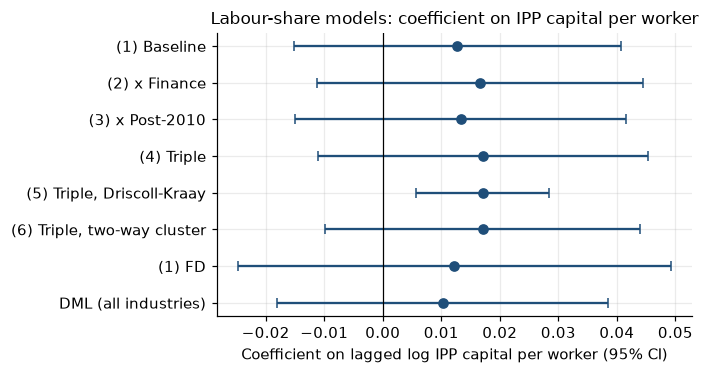

In [14]:
rows = []
for t in h3_models + fd[:1]:
    term = "d_L_ipp" if "FD" in t.model.iloc[0] else "L_ipp"
    r = t[t.term == term]
    if len(r):
        rows.append((t.model.iloc[0], r.coef.iloc[0], r.ci_low.iloc[0], r.ci_high.iloc[0]))
rows.append(("DML (all industries)", dml_tab.theta.iloc[0], dml_tab.ci_low.iloc[0], dml_tab.ci_high.iloc[0]))
cp = pd.DataFrame(rows, columns=["model", "coef", "lo", "hi"])
fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.errorbar(cp.coef, range(len(cp)), xerr=[cp.coef - cp.lo, cp.hi - cp.coef], fmt="o", color=st.PALETTE["finance"], capsize=3)
ax.axvline(0, color="k", lw=0.8); ax.set_yticks(range(len(cp))); ax.set_yticklabels(cp.model)
ax.set_xlabel("Coefficient on lagged log IPP capital per worker (95% CI)"); ax.invert_yaxis()
ax.set_title("Labour-share models: coefficient on IPP capital per worker")
st.savefig(fig, "fig9_h3_coefficients"); plt.show()

## Multiple-testing correction and hypothesis verdicts

Each hypothesis has an expected sign. The test is one-sided in that direction: an estimate with the *wrong* sign gets a p-value near 1, however precisely it is estimated. One-sided p-values are then Holm–Bonferroni adjusted across all headline tests.

In [15]:
summary = pd.DataFrame(TESTS).set_index("hypothesis")
summary["sign_as_expected"] = np.where(summary.expected_sign == "+", summary.estimate > 0, summary.estimate < 0)
summary["p_holm"] = st.holm(summary["p_one_sided"])
summary["supported_5pct_holm"] = summary["p_holm"] < 0.05
st.save_table(summary.round(4), "hypothesis_summary", caption="Hypothesis tests with Holm-Bonferroni adjustment")
summary.round(4)

,expected_sign,estimate,p_two_sided,p_one_sided,sign_as_expected,p_holm,supported_5pct_holm
hypothesis,,,,,,,
H1a Finance IPP stock grows (trend growth > 0),+,0.0775,0.0000,0.0000,True,0.0000,True
H1b Finance IPP growth premium,+,0.0228,0.0013,0.0007,True,0.0061,True
H1b Extra post-2010 acceleration in finance,+,-0.0096,0.5367,0.7316,False,1.0000,False
H1c Finance IPP growth higher after 2010 (HAC),+,0.0172,0.4399,0.2199,True,1.0000,False
H2 IPP intensity widens the productivity-pay gap (all),+,0.0190,0.6798,0.3399,True,1.0000,False
H2 ... in finance (beta + beta_fin),+,-0.1133,0.2188,0.8906,False,1.0000,False
H3 IPP intensity lowers the labour share (all),-,0.0128,0.3696,0.8152,False,1.0000,False
H3 Net effect in finance (beta + beta_fin),-,-0.0399,0.0014,0.0007,True,0.0061,True
"H3 Effect more negative in finance (beta_fin, randomization p)",-,-0.0565,0.1718,0.0859,True,0.6014,False


**Reading the results (for the paper):** report the sign and size of the H3 coefficients alongside the H1 growth rates and break tests. Note that H2's gap includes a price-wedge component (the decomposition above), so the H3 labour-share results are the cleaner test of distributional effects.